# Лабораторна робота № 3
## Діагностика шкал вимірювання

Курс СК26 «Інтелектуальний аналіз та візуалізація даних»

**Тривалість:** 2 год аудиторно + 3 год самостійно · **Оцінка:** 4 бали
**Файли:** `Ковід_дані_навчальні.xlsx`, `ЛР3_помилковий_аналіз.ipynb`

---

Шкала вимірювання визначає, які операції над змінною взагалі мають сенс.
Комп'ютер цього не знає: він порахує середнє від номера телефону й не поскаржиться.
Знати має вимірювач.

У цій роботі ви складаєте **паспорт восьми змінних** свого варіанта, показуєте на
власних даних, які статистики для них недопустимі, і виправляєте чужий аналіз,
де таких помилок десять.

In [1]:
ПРІЗВИЩЕ_ІМЯ = 'Єдинець Євген'
ГРУПА        = 'ШІ-31'
НОМЕР        = 6  # Номер за списком групи (не довільний номер варіанта)

assert ПРІЗВИЩЕ_ІМЯ and ГРУПА and НОМЕР, 'Заповніть три поля вище'
assert 1 <= НОМЕР <= 30, 'Номер має бути від 1 до 30'

In [2]:
import json
import re
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, chi2_contingency
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

pd.set_option('display.max_colwidth', 105)
pd.set_option('display.width', 135)

# Файл варіантів лежить поруч із ноутбуком і включений у ZIP-пакет.
ВАРІАНТИ = json.loads(Path('lr3_variants_student.json').read_text(encoding='utf-8'))
В = ВАРІАНТИ[НОМЕР - 1]
assert В['варіант'] == 6

print('=' * 74)
print(f'ВАРІАНТ {В["варіант"]}   ·   {ПРІЗВИЩЕ_ІМЯ}   ·   {ГРУПА}')
print('=' * 74)
print('\nВаші вісім стовпців:')
for i, c in enumerate(В['стовпці'], 1):
    print(f'  {i}. {c}')
print('\nПара змінних:', ' та '.join(В['пара']))
print('\nІндивідуальне питання:', В['питання'])

ВАРІАНТ 6   ·   Єдинець Євген   ·   ШІ-31

Ваші вісім стовпців:
  1. ПІП
  2. Примітка
  3. Перебіг
  4. Дата розтину
  5. Ліжко днів
  6. Т вище38
  7. МНВ1
  8. Креат2

Пара змінних: Ліжко днів та Вік

Індивідуальне питання: Скільки стовпців файлу є ідентифікаторами? Як їх розпізнати автоматично, не дивлячись на назви?


In [3]:
ФАЙЛ = 'Ковід_дані_навчальні.xlsx'
df = pd.read_excel(ФАЙЛ, sheet_name='Лист1', engine='openpyxl')
МОЇ = В['стовпці']
assert df.shape == (121, 77), 'Розмір вихідних даних відрізняється від методички'
assert set(МОЇ).issubset(df.columns)
print('Розмір набору:', df.shape)
display(df[МОЇ].head(8))

Розмір набору: (121, 77)


,ПІП,Примітка,Перебіг,Дата розтину,Ліжко днів,Т вище38,МНВ1,Креат2
0,Федорюк Петро Юрійович,NaN,важкий,2022-03-11,14,4 дні до госп,3.10,92
1,Загул Григорій Сергійович,"отримував актемра, часті носові кровотечі, втрата нюху",важкий,NaT,22,5 до гос,1.22,73
2,Бондара Лариса Павлівна,часта втрата свідомосі в стаціонарі,важкий,NaT,20,10 до гос,1.03,117.2
3,Ватаманюка Уляна Дмитрівна,панкреонекроз,важкий,NaT,20,9 до гос,1.69,105.1
4,Бабійа Лариса Олегівна,NaN,важкий,NaT,27,NaN,1.15,101
5,Ковалика ганна Андріївна,NaN,важкий,2021-12-26,9(5 у реан),NaN,0.90,172
6,Височан Віктор Володимирович,"глюкозурія, кетонові тіла в сечі, ЦД, фібриляція передс",важкий,NaT,18,7 дні до госп,1.09,97.8
7,Дзюбаа Ірина Іванівна,NaN,серед важ,NaT,10,9 днів до госп,0.94,107


In [4]:
ПОРЯДОК_ПЕРЕБІГУ = ['серед важ', 'важкий', 'вкрай важкий']


def дні_ліжка(v):
    if pd.isna(v):
        return np.nan
    текст = str(v).strip()
    # «9(5 у реан)» означає дев'ять діб загалом, а не 9 + 5.
    m = re.fullmatch(r'(\d+)(?:\s*\(\s*\d+\s*у\s*реан\s*\))?', текст, re.I)
    return float(m.group(1)) if m else np.nan


def дні_понад_38(v):
    if pd.isna(v):
        return np.nan
    текст = str(v).lower().strip()
    числа = [float(x.replace(',', '.')) for x in re.findall(r'\d+(?:[.,]\d+)?', текст)]
    if not числа:
        return np.nan
    # «7 днів до госп + відд» має невідому додаткову тривалість.
    if '+' in текст and len(числа) == 1:
        return np.nan
    # «5 днів до госп + 3 дні в стац» — сумарно 8 днів.
    if '+' in текст and len(числа) == 2:
        return sum(числа)
    return числа[0] if len(числа) == 1 else np.nan


def чистий_перебіг(v):
    if pd.isna(v):
        return np.nan
    текст = str(v).strip().lower()
    return текст if текст in ПОРЯДОК_ПЕРЕБІГУ else np.nan


ОЧИЩЕНІ = {
    'ПІП': df['ПІП'].astype('string').str.strip(),
    'Примітка': df['Примітка'].astype('string').str.strip().replace('', pd.NA),
    'Перебіг': df['Перебіг'].map(чистий_перебіг),
    'Дата розтину': pd.to_datetime(df['Дата розтину'], errors='coerce'),
    'Ліжко днів': df['Ліжко днів'].map(дні_ліжка),
    'Т вище38': df['Т вище38'].map(дні_понад_38),
    'МНВ1': pd.to_numeric(df['МНВ1'], errors='coerce'),
    'Креат2': pd.to_numeric(df['Креат2'], errors='coerce'),
}

звіт_очищення = pd.DataFrame([
    {'Стовпець': c, 'Непорожніх в оригіналі': int(df[c].notna().sum()),
     'Інтерпретованих після очищення': int(ОЧИЩЕНІ[c].notna().sum())}
    for c in МОЇ
])
display(звіт_очищення)
print('Важливо: оригінальний набір даних не змінено.')

,Стовпець,Непорожніх в оригіналі,Інтерпретованих після очищення
0,ПІП,121,121
1,Примітка,45,44
2,Перебіг,121,121
3,Дата розтину,61,61
4,Ліжко днів,120,120
5,Т вище38,77,76
6,МНВ1,90,90
7,Креат2,102,101


Важливо: оригінальний набір даних не змінено.


### Підготовка до аналізу: зберігаємо оригінал і створюємо очищені представлення

Для цієї лабораторної **шкали встановлюємо за змістом величин**, а не за `dtype`. Оригінальний `df` не перезаписуємо: це дає змогу відтворити помилки з чужого звіту і порівняти їх із правильними розрахунками.

Особливості варіанта: `Ліжко днів` містить `9(5 у реан)` (9 днів загалом, 5 із них у реанімації); `Т вище38` містить описи кількості днів та періоду; `Креат2` містить текстове `немає`; `Перебіг` має три впорядковані категорії. Невідоме не вважаємо нулем, а для неоднозначного `+ відд` не вигадуємо тривалість.

---
# Етап 1. Паспорт змінних

Для кожного з восьми стовпців визначте шкалу вимірювання. Спирайтеся не на тип даних
у pandas, а на **зміст величини**: що означають її значення і які порівняння між ними
мають сенс.

Нагадування:

| Шкала | Ознака |
|---|---|
| Номінальна | значення можна лише порівняти на рівність |
| Порядкова | є природний порядок, але відстані між сусідніми рівнями невідомі |
| Інтервальна | різниці мають сенс, нуль умовний |
| Відношень | є природний нуль, відношення мають сенс |
| Абсолютна | природні і нуль, і одиниця вимірювання |

Окремо позначайте **ідентифікатори** — значення, що не є величиною взагалі
(номер історії хвороби, прізвище, телефон).

In [5]:
# Спершу подивіться, що каже pandas — і не довіряйте йому
df[МОЇ].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   ПІП           121 non-null    object        
 1   Примітка      45 non-null     object        
 2   Перебіг       121 non-null    object        
 3   Дата розтину  61 non-null     datetime64[ns]
 4   Ліжко днів    120 non-null    object        
 5   Т вище38      77 non-null     object        
 6   МНВ1          90 non-null     float64       
 7   Креат2        102 non-null    object        
dtypes: datetime64[ns](1), float64(1), object(6)
memory usage: 7.7+ KB


In [6]:
# Далі — що є всередині насправді
for c in МОЇ:
    з = df[c].dropna()
    типи = ', '.join(f'{t.__name__}×{n}' for t, n in з.map(type).value_counts().items())
    print(f'--- {c}')
    print(f'    непорожніх {len(з)} з {len(df)} | унікальних {з.nunique()} | типи: {типи}')
    print(f'    приклади: {[repr(v) for v in з.unique()[:4]]}')
    print()

--- ПІП
    непорожніх 121 з 121 | унікальних 121 | типи: str×121
    приклади: ["'Федорюк Петро Юрійович'", "'Загул Григорій Сергійович'", "'Бондара Лариса Павлівна'", "'Ватаманюка Уляна Дмитрівна'"]

--- Примітка
    непорожніх 45 з 121 | унікальних 44 | типи: str×45
    приклади: ["'отримував актемра, часті носові кровотечі, втрата нюху'", "'часта втрата свідомосі в стаціонарі'", "'панкреонекроз'", "'глюкозурія, кетонові тіла в сечі, ЦД, фібриляція передс'"]

--- Перебіг
    непорожніх 121 з 121 | унікальних 3 | типи: str×121
    приклади: ["'важкий'", "'серед важ'", "'вкрай важкий '"]

--- Дата розтину
    непорожніх 61 з 121 | унікальних 50 | типи: Timestamp×61
    приклади: ["Timestamp('2022-03-11 00:00:00')", "Timestamp('2021-12-26 00:00:00')", "Timestamp('2021-11-19 00:00:00')", "Timestamp('2022-05-13 00:00:00')"]

--- Ліжко днів
    непорожніх 120 з 121 | унікальних 40 | типи: int×119, str×1
    приклади: ['14', '22', '20', '27']

--- Т вище38
    непорожніх 77 з 121 | унікаль

### Заповніть паспорт

Для кожного стовпця вкажіть шкалу та **обґрунтування** — одне речення про те,
чому саме ця шкала. Обґрунтування оцінюється, назва шкали сама по собі — ні.

In [7]:
ПАСПОРТ = {
    'ПІП': ('ідентифікатор',
            'Повне ім’я є позначенням особи: значення ідентифікують записи, але не мають числового порядку, різниць чи одиниць вимірювання.'),
    'Примітка': ('номінальна',
                'Це вільний текст із клінічними описами; окремі записи є текстовими категоріями без природного порядку, а не числовою величиною.'),
    'Перебіг': ('порядкова',
                'Середньоважкий, важкий та вкрай важкий перебіг можна впорядкувати за тяжкістю, але відстані між рівнями невідомі.'),
    'Дата розтину': ('інтервальна',
                     'Календарні дати можна віднімати й отримувати тривалість у днях, однак нуль календаря умовний, тож відношення дат не мають сенсу.'),
    'Ліжко днів': ('відношень',
                   'Тривалість госпіталізації виміряна в днях: є змістовний нуль, а 20 днів удвічі довше, ніж 10 днів.'),
    'Т вище38': ('відношень',
                 'Це тривалість підвищеної температури в днях: нуль означає нуль днів, а співвідношення тривалостей осмислені після очищення описів.'),
    'МНВ1': ('відношень',
              'Міжнародне нормалізоване відношення є невід’ємним кількісним показником на шкалі співвідношень з осмисленими пропорціями.'),
    'Креат2': ('відношень',
               'Показник креатиніну є кількісною концентрацією з фізичним нулем: різниці та відношення можливі після очищення значень.'),
}

паспорт_df = pd.DataFrame(
    [(c, ПАСПОРТ[c][0], ПАСПОРТ[c][1]) for c in МОЇ],
    columns=['Стовпець', 'Шкала', 'Обґрунтування'])
display(паспорт_df)

,Стовпець,Шкала,Обґрунтування
0,ПІП,ідентифікатор,"Повне ім’я є позначенням особи: значення ідентифікують записи, але не мають числового порядку, різниц..."
1,Примітка,номінальна,Це вільний текст із клінічними описами; окремі записи є текстовими категоріями без природного порядку...
2,Перебіг,порядкова,"Середньоважкий, важкий та вкрай важкий перебіг можна впорядкувати за тяжкістю, але відстані між рівня..."
3,Дата розтину,інтервальна,"Календарні дати можна віднімати й отримувати тривалість у днях, однак нуль календаря умовний, тож від..."
4,Ліжко днів,відношень,"Тривалість госпіталізації виміряна в днях: є змістовний нуль, а 20 днів удвічі довше, ніж 10 днів."
5,Т вище38,відношень,"Це тривалість підвищеної температури в днях: нуль означає нуль днів, а співвідношення тривалостей осм..."
6,МНВ1,відношень,Міжнародне нормалізоване відношення є невід’ємним кількісним показником на шкалі співвідношень з осми...
7,Креат2,відношень,Показник креатиніну є кількісною концентрацією з фізичним нулем: різниці та відношення можливі після ...


In [8]:
# --- САМОПЕРЕВІРКА 1 ---
ДОПУСТИМІ = {'номінальна', 'порядкова', 'інтервальна', 'відношень',
             'абсолютна', 'ідентифікатор'}
for c in МОЇ:
    ш, об = ПАСПОРТ[c]
    assert ш.strip().lower() in ДОПУСТИМІ, f'{c}: шкалу «{ш}» не розпізнано'
    assert len(об.strip()) >= 25, f'{c}: обґрунтування закоротке'
print('Самоперевірка 1 пройдена: усі вісім стовпців мають шкалу та обґрунтування.')

Самоперевірка 1 пройдена: усі вісім стовпців мають шкалу та обґрунтування.


**Уточнення щодо шкал.** Відсутність природного числового змісту в `ПІП` не виправляється кодуванням числами. Для `Примітка` це номінальне, але **неструктуроване текстове** поле, тому частоти дослівних фраз ще не є частотами діагнозів. Числові лабораторні величини мають перевірятися на одиниці вимірювання та аномалії: автоматичне приведення типу цього не гарантує. Дата розтину також є **післяподієвою інформацією** і не підходить як ознака прогнозу на момент госпіталізації.

---
# Етап 2. Допустимі статистики

Для кожного стовпця обчисліть **тільки те, що дозволяє його шкала**.

* номінальна та ідентифікатор — мода, частоти
* порядкова — додатково медіана та квантилі
* інтервальна — додатково середнє та стандартне відхилення
* відношень і абсолютна — усе, зокрема коефіцієнт варіації

Якщо для стовпця не можна порахувати нічого, крім частот, — так і напишіть.

In [9]:
def порядкова_квантиль(с, q):
    коди = с.dropna().map({v: i for i, v in enumerate(ПОРЯДОК_ПЕРЕБІГУ)})
    впорядковані = np.sort(коди.dropna().to_numpy(dtype=int))
    if not len(впорядковані):
        return None
    позиція = int(round((len(впорядковані) - 1) * q))
    return ПОРЯДОК_ПЕРЕБІГУ[впорядковані[позиція]]


def допустима_статистика(стовпець, шкала):
    """Лише статистики, які має сенс інтерпретувати для цієї шкали."""
    з = ОЧИЩЕНІ[стовпець].dropna()
    р = {'непорожніх (після очищення)': int(len(з)),
         'унікальних': int(з.nunique())}
    ш = шкала.strip().lower()

    if ш == 'ідентифікатор':
        # Унікальність / кількість — характеристика ключа, а не середнє ПІП.
        return р

    р['частоти, топ-5'] = з.value_counts().head(5).to_dict()
    р['мода'] = str(з.mode().iloc[0]) if len(з) else None

    if ш == 'номінальна':
        return р

    if ш == 'порядкова':
        р['Q1'] = порядкова_квантиль(з, 0.25)
        р['медіана'] = порядкова_квантиль(з, 0.50)
        р['Q3'] = порядкова_квантиль(з, 0.75)
        return р

    if ш == 'інтервальна':
        if len(з):
            р['середня дата'] = str(з.mean().date())
            р['найраніша'] = str(з.min().date())
            р['найпізніша'] = str(з.max().date())
            р['станд. відхилення, діб'] = round(з.std().total_seconds() / 86400, 2)
        return р

    if ш in ('відношень', 'абсолютна'):
        числа = pd.to_numeric(з, errors='coerce').dropna()
        if len(числа):
            р['мінімум'] = round(float(числа.min()), 3)
            р['медіана'] = round(float(числа.median()), 3)
            р['середнє'] = round(float(числа.mean()), 3)
            р['станд. відхилення'] = round(float(числа.std()), 3)
            р['максимум'] = round(float(числа.max()), 3)
            if len(числа) >= 2 and числа.mean() > 0:
                р['коеф. варіації, %'] = round(float(100 * числа.std() / числа.mean()), 2)
        return р
    raise ValueError(f'Невідома шкала: {ш}')


СТАТИСТИКИ = {c: допустима_статистика(c, ПАСПОРТ[c][0]) for c in МОЇ}
for c, показники in СТАТИСТИКИ.items():
    print(f'--- {c} ({ПАСПОРТ[c][0]})')
    for назва, значення in показники.items():
        print(f'  {назва}: {значення}')
    print()

--- ПІП (ідентифікатор)
  непорожніх (після очищення): 121
  унікальних: 121

--- Примітка (номінальна)
  непорожніх (після очищення): 44
  унікальних: 42
  частоти, топ-5: {'Поліалергетик': 2, 'ЦД вперше виявлений': 2, 'екстерпація маки, медикаментозна алеогрія': 1, 'переливання еритроцитарної маси': 1, 'панкреонекроз': 1}
  мода: Поліалергетик

--- Перебіг (порядкова)
  непорожніх (після очищення): 121
  унікальних: 3
  частоти, топ-5: {'важкий': 90, 'серед важ': 30, 'вкрай важкий': 1}
  мода: важкий
  Q1: важкий
  медіана: важкий
  Q3: важкий

--- Дата розтину (інтервальна)
  непорожніх (після очищення): 61
  унікальних: 50
  частоти, топ-5: {Timestamp('2022-06-07 00:00:00'): 3, Timestamp('2022-05-06 00:00:00'): 2, Timestamp('2022-05-22 00:00:00'): 2, Timestamp('2022-04-13 00:00:00'): 2, Timestamp('2022-04-27 00:00:00'): 2}
  мода: 2022-06-07 00:00:00
  середня дата: 2022-04-06
  найраніша: 2021-01-06
  найпізніша: 2022-06-22
  станд. відхилення, діб: 72.57

--- Ліжко днів (відношен

Для порядкового `Перебіг` квартилі беруться **серед наявних рівнів тяжкості**, без штучного усереднення кодів. Для `Дата розтину` середня дата й розсіювання в добах описують лише пацієнтів із записаною датою розтину, а **не всіх 121 пацієнтів**. Для тривалостей та лабораторних показників пропуски не замінено нулями. Показник `МНВ1` має великі крайні значення; без первинної документації не можна автоматично оголосити їх помилками чи видалити.

---
# Етап 3. Три безглузді числа

`df.describe()` порахує статистики для всього, що схоже на число. Частина цих чисел
не має жодного змісту.

Знайдіть **щонайменше три** такі числа у своєму наборі: обчисліть їх, а потім
поясніть, чому кожне з них безглузде.

In [10]:
df[МОЇ].describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ПІП,121,121,Федорюк Петро Юрійович,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Примітка,45,44,Поліалергетик,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Перебіг,121,3,важкий,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Дата розтину,61,NaN,NaN,NaN,2022-04-06 13:22:37.377049088,2021-01-06 00:00:00,2022-03-29 00:00:00,2022-04-23 00:00:00,2022-05-07 00:00:00,2022-06-22 00:00:00,NaN
Ліжко днів,120.0,40.0,10.0,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Т вище38,77.0,28.0,3.0,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
МНВ1,90.0,NaN,NaN,NaN,1.333778,0.8,1.0525,1.19,1.34,10.6,1.032131
Креат2,102.0,72.0,77.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# Кодування лише для демонстрації методологічної помилки — НЕ для медичної інтерпретації.
коди_піп = pd.Series(pd.factorize(ОЧИЩЕНІ['ПІП'])[0] + 1, index=df.index)
коди_перебігу = ОЧИЩЕНІ['Перебіг'].map({'серед важ': 1, 'важкий': 2, 'вкрай важкий': 3})
дата_число = ОЧИЩЕНІ['Дата розтину'].dropna().map(lambda d: d.timestamp() / 86400)

БЕЗГЛУЗДІ = [
    ('ПІП', 'середнє від довільного коду імен', round(float(коди_піп.mean()), 3),
     'Імена — ідентифікатори. Коди призначені довільно, тому їхнє середнє не описує жодну властивість людей.'),
    ('Перебіг', 'середнє від кодів тяжкості 1–3', round(float(коди_перебігу.mean()), 3),
     'Шкала порядкова: проміжки між середньоважким, важким і вкрай важким невідомі; арифметичне середнє кодів залежить від кодування.'),
    ('Дата розтину', 'CV дат, записаних як дні від 1970-01-01, %',
     round(float(100 * дата_число.std() / дата_число.mean()), 4),
     'Дата — інтервальна шкала з умовним початком. CV змінюється, коли змінюється календарна точка відліку, і не характеризує однорідність дат.'),
]

display(pd.DataFrame(БЕЗГЛУЗДІ,
    columns=['Стовпець', 'Статистика', 'Значення', 'Чому безглузде']))

# Перевірка довільності: перестановка кодів не змінює пацієнтів, але змінює число.
інша_нумерація = ОЧИЩЕНІ['Перебіг'].map({'серед важ': 1, 'важкий': 2, 'вкрай важкий': 100})
print('Середній код перебігу 1/2/3  :', round(коди_перебігу.mean(), 3))
print('Середній код перебігу 1/2/100:', round(інша_нумерація.mean(), 3))

,Стовпець,Статистика,Значення,Чому безглузде
0,ПІП,середнє від довільного коду імен,61.0000,"Імена — ідентифікатори. Коди призначені довільно, тому їхнє середнє не описує жодну властивість людей."
1,Перебіг,середнє від кодів тяжкості 1–3,1.7600,"Шкала порядкова: проміжки між середньоважким, важким і вкрай важким невідомі; арифметичне середнє код..."
2,Дата розтину,"CV дат, записаних як дні від 1970-01-01, %",0.3802,"Дата — інтервальна шкала з умовним початком. CV змінюється, коли змінюється календарна точка відліку,..."


Середній код перебігу 1/2/3  : 1.76
Середній код перебігу 1/2/100: 2.562


---
# Етап 4. Міра зв'язку для вашої пари

Для двох змінних вашого варіанта треба оцінити зв'язок. Міру обирає **пара шкал**,
а не зручність:

| Поєднання шкал | Міра |
|---|---|
| відношень × відношень | кореляція Пірсона |
| порядкова × порядкова | рангова кореляція Спірмена |
| номінальна × номінальна | χ² та коефіцієнт Крамера (V) |
| відношень × бінарна номінальна | точковий бісеріальний коефіцієнт |
| номінальна × порядкова | коефіцієнт Крамера (V) |

Обґрунтуйте вибір, обчисліть міру й поясніть результат. Окремо покажіть, **що
станеться**, якщо застосувати Пірсона там, де він недопустимий, — і чому отримане
число не можна інтерпретувати.

In [12]:
A, B = В['пара']
print('Ваша пара:', A, '×', B)
print()
print(f'{A}: шкала —', ПАСПОРТ.get(A, ('не у вашому списку',))[0] or '(визначте самостійно)')
print(f'{B}: шкала —', ПАСПОРТ.get(B, ('не у вашому списку',))[0] or '(визначте самостійно)')
print()
print(df[[A, B]].head(6).to_string())

Ваша пара: Ліжко днів × Вік

Ліжко днів: шкала — відношень
Вік: шкала — не у вашому списку

    Ліжко днів  Вік
0           14   55
1           22   43
2           20   54
3           20   68
4           27   65
5  9(5 у реан)   66


Обрана міра: коефіцієнт кореляції Пірсона (r)
Обґрунтування: «Ліжко днів» і «Вік» є кількісними змінними шкали відношень, тому кореляція Пірсона допустима для оцінювання саме лінійного зв’язку. Спочатку потрібно очистити тривалість, перевірити парні пропуски, після чого відрізняти описову кореляцію від причинного висновку.
n = 120, r = -0.0996, p = 0.2791
95% довірчий інтервал r (наближення Фішера): [-0.2740, 0.0811]
Висновок: лінійний зв’язок слабкий; на рівні 0.05 він статистично не підтверджений.


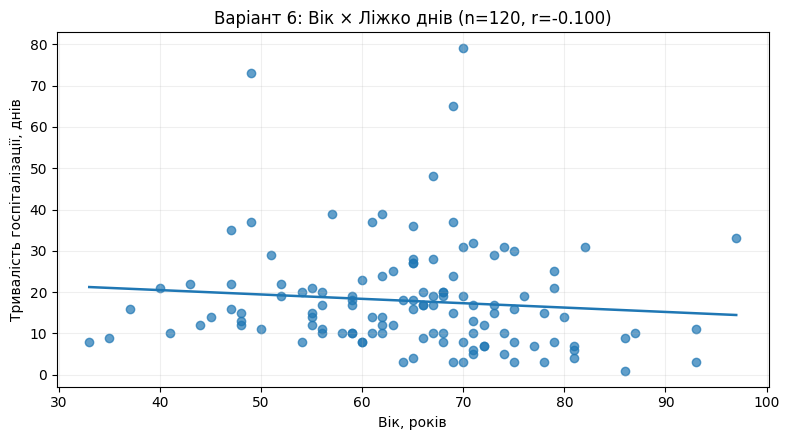

In [13]:
ОБРАНА_МІРА = 'коефіцієнт кореляції Пірсона (r)'
ЧОМУ_САМЕ_ВОНА = (
    '«Ліжко днів» і «Вік» є кількісними змінними шкали відношень, '
    'тому кореляція Пірсона допустима для оцінювання саме лінійного зв’язку. '
    'Спочатку потрібно очистити тривалість, перевірити парні пропуски, '
    'після чого відрізняти описову кореляцію від причинного висновку.'
)
assert ОБРАНА_МІРА and len(ЧОМУ_САМЕ_ВОНА) >= 40

пара = pd.DataFrame({
    'Ліжко днів': ОЧИЩЕНІ['Ліжко днів'],
    'Вік': pd.to_numeric(df['Вік'], errors='coerce')
}).dropna()

r, p = pearsonr(пара['Ліжко днів'], пара['Вік'])
n = len(пара)
зсув = np.arctanh(r)
похибка = 1 / np.sqrt(n - 3)
ci95 = (np.tanh(зсув - 1.96 * похибка), np.tanh(зсув + 1.96 * похибка))

print('Обрана міра:', ОБРАНА_МІРА)
print('Обґрунтування:', ЧОМУ_САМЕ_ВОНА)
print(f'n = {n}, r = {r:.4f}, p = {p:.4f}')
print(f'95% довірчий інтервал r (наближення Фішера): [{ci95[0]:.4f}, {ci95[1]:.4f}]')
print('Висновок: лінійний зв’язок слабкий; на рівні 0.05 він статистично не підтверджений.')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(пара['Вік'], пара['Ліжко днів'], alpha=0.7)
coef = np.polyfit(пара['Вік'], пара['Ліжко днів'], 1)
xline = np.array([пара['Вік'].min(), пара['Вік'].max()])
ax.plot(xline, np.polyval(coef, xline), linewidth=1.8)
ax.set(xlabel='Вік, років', ylabel='Тривалість госпіталізації, днів',
       title=f'Варіант 6: Вік × Ліжко днів (n={n}, r={r:.3f})')
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

In [14]:
# Контрприклад НЕПРИПУСТИМОГО Пірсона: ПІП (ідентифікатор) × тривалість.
# Формально можна зробити числа, але їхній порядок нічого не означає.
коди_імен = pd.Series(pd.factorize(ОЧИЩЕНІ['ПІП'])[0], index=df.index, dtype=float)
п = pd.DataFrame({'код': коди_імен, 'ліжко': ОЧИЩЕНІ['Ліжко днів']}).dropna()
пірсон_а = п['код'].corr(п['ліжко'])
пірсон_б = (-п['код']).corr(п['ліжко'])
print(f'Пірсон для довільних номерів ПІП:       {пірсон_а:.4f}')
print(f'Пірсон після зміни нумерації на від’ємну: {пірсон_б:.4f}')
print('Ті самі люди й тривалості, але знак кореляції перевернувся.')
print('Отже, це не зв’язок властивостей, а артефакт кодування ідентифікаторів.')
print('Для нашої правильної пари «Ліжко днів» × «Вік» Пірсон, навпаки, ДОПУСТИМИЙ.')

Пірсон для довільних номерів ПІП:       0.0164
Пірсон після зміни нумерації на від’ємну: -0.0164
Ті самі люди й тривалості, але знак кореляції перевернувся.
Отже, це не зв’язок властивостей, а артефакт кодування ідентифікаторів.
Для нашої правильної пари «Ліжко днів» × «Вік» Пірсон, навпаки, ДОПУСТИМИЙ.


---
# Етап 5. Підготовка змінних до моделі

Шкала визначає не лише статистику, а й спосіб кодування.

| Шкала | Як готують до моделі |
|---|---|
| Номінальна | one-hot кодування; порядок категорій не вводять |
| Порядкова | впорядкована категорія або цілі коди із **заданим** порядком |
| Інтервальна | стандартизація; для дат — перехід до тривалостей |
| Відношень | нормалізація або стандартизація; можливе логарифмування |
| Ідентифікатор | у модель не беруть узагалі |

Для кожного свого стовпця вкажіть спосіб підготовки — і **виконайте його**
щонайменше для трьох стовпців різних шкал.

In [15]:
ПІДГОТОВКА = {
    'ПІП': 'Ідентифікатор: не передавати в ML-модель, використовувати лише для зв’язування записів; видалити із матриці ознак.',
    'Примітка': 'Неструктурований номінальний текст: пропуски позначити окремо; для демонстрації one-hot, для реальної моделі — перевірений словник медичних ознак або текстові ембеддинги.',
    'Перебіг': 'Порядкова: вручну задати послідовність серед важ < важкий < вкрай важкий; перетворити на 0/1/2 або впорядковану категорію.',
    'Дата розтину': 'Інтервальна дата: для опису перевести у часові інтервали або відлік від базової дати; для прогнозу на момент поступлення ВИКЛЮЧИТИ як витік інформації.',
    'Ліжко днів': 'Кількісна шкала відношень: очистити 9(5 у реан) до 9; пропуски імпутувати за train, числову ознаку стандартизувати за train.',
    'Т вище38': 'Кількісна шкала відношень: витягти дні, окремо перевіряти «до госп»/«в стац» і неоднозначні значення; імпутація та стандартизація лише на train.',
    'МНВ1': 'Кількісна шкала відношень: зберегти фізичний зміст, перевірити крайні значення; числове перетворення, імпутація та стандартизація лише на train.',
    'Креат2': 'Кількісна шкала відношень: «немає» трактувати як пропуск, не як нуль; числове перетворення, імпутація та стандартизація лише на train.',
}
for c in МОЇ:
    ПІДГОТОВКА.setdefault(c, '')
display(pd.DataFrame([(c, ПАСПОРТ[c][0], ПІДГОТОВКА[c]) for c in МОЇ],
   columns=['Стовпець', 'Шкала', 'Як готуємо']))

,Стовпець,Шкала,Як готуємо
0,ПІП,ідентифікатор,"Ідентифікатор: не передавати в ML-модель, використовувати лише для зв’язування записів; видалити із м..."
1,Примітка,номінальна,"Неструктурований номінальний текст: пропуски позначити окремо; для демонстрації one-hot, для реальної..."
2,Перебіг,порядкова,Порядкова: вручну задати послідовність серед важ < важкий < вкрай важкий; перетворити на 0/1/2 або вп...
3,Дата розтину,інтервальна,Інтервальна дата: для опису перевести у часові інтервали або відлік від базової дати; для прогнозу на...
4,Ліжко днів,відношень,"Кількісна шкала відношень: очистити 9(5 у реан) до 9; пропуски імпутувати за train, числову ознаку ст..."
5,Т вище38,відношень,"Кількісна шкала відношень: витягти дні, окремо перевіряти «до госп»/«в стац» і неоднозначні значення;..."
6,МНВ1,відношень,"Кількісна шкала відношень: зберегти фізичний зміст, перевірити крайні значення; числове перетворення,..."
7,Креат2,відношень,"Кількісна шкала відношень: «немає» трактувати як пропуск, не як нуль; числове перетворення, імпутація..."


In [16]:
# Практично виконуємо 3 різні шкали: номінальна, порядкова, відношень.
# Усі параметри перетворень із навчанням обчислюємо ЛИШЕ на тренувальній частині.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=.25,
                                       random_state=42)

# 1) Примітка, НОМІНАЛЬНА: one-hot точних значень (навчальна демонстрація).
# У реальному застосуванні висококардинальні тексти доцільно обробляти NLP,
# а не мати по стовпцю для кожного унікального тексту.
тексти = ОЧИЩЕНІ['Примітка'].fillna('не записано').astype(str).to_frame()
try:
    enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:  # сумісність зі старішим sklearn
    enc = OneHotEncoder(handle_unknown='ignore', sparse=False)
X_ном_train = enc.fit_transform(тексти.iloc[idx_train])
X_ном_test = enc.transform(тексти.iloc[idx_test])

# 2) Перебіг, ПОРЯДКОВА: явно заданий порядок, без алфавітного сортування.
коди_порядкові = {'серед важ': 0, 'важкий': 1, 'вкрай важкий': 2}
X_порядок = ОЧИЩЕНІ['Перебіг'].map(коди_порядкові)
assert X_порядок.notna().all()

# 3) Ліжко днів, ВІДНОШЕНЬ: імпутація медіаною + StandardScaler, fit лише на train.
числовий = ОЧИЩЕНІ['Ліжко днів'].to_frame()
imp = SimpleImputer(strategy='median')
sc = StandardScaler()
X_чис_train = sc.fit_transform(imp.fit_transform(числовий.iloc[idx_train]))
X_чис_test = sc.transform(imp.transform(числовий.iloc[idx_test]))

print(f'Номінальна «Примітка»: train {X_ном_train.shape}, test {X_ном_test.shape}')
print(f'Порядкова «Перебіг»: {коди_порядкові}, частоти: {X_порядок.value_counts().to_dict()}')
print(f'Відношень «Ліжко днів»: train mean={X_чис_train.mean():.6f}, std={X_чис_train.std():.6f}')
print(f'Числова ознака test: {len(X_чис_test)} спостережень; train median={imp.statistics_[0]}')

# Додатковий індикатор наявності запису: не замінює зміст тексту.
наявність_примітки = ОЧИЩЕНІ['Примітка'].notna().astype(int)
print('Є текст примітки:', int(наявність_примітки.sum()), 'із', len(df))

Номінальна «Примітка»: train (90, 34), test (31, 34)
Порядкова «Перебіг»: {'серед важ': 0, 'важкий': 1, 'вкрай важкий': 2}, частоти: {1: 90, 0: 30, 2: 1}
Відношень «Ліжко днів»: train mean=-0.000000, std=1.000000
Числова ознака test: 31 спостережень; train median=15.0
Є текст примітки: 44 із 121


In [17]:
# Безпечна min-max нормалізація: демонструємо поведінку на сталому стовпці.
def безпечний_minmax(s):
    s = pd.to_numeric(s, errors='coerce')
    ненульові = s.dropna()
    if ненульові.empty:
        return pd.Series(np.nan, index=s.index, dtype=float)
    розмах = ненульові.max() - ненульові.min()
    if np.isclose(розмах, 0):
        # Константа не несе варіативної інформації; позначаємо нулями.
        return pd.Series(np.where(s.notna(), 0.0, np.nan), index=s.index, dtype=float)
    return (s - ненульові.min()) / розмах

стала = pd.Series([3.0, 3.0, 3.0])
наївна = (стала - стала.min()) / (стала.max() - стала.min())
виправлена = безпечний_minmax(стала)
print('Стала ознака, наївна нормалізація:', наївна.tolist())
print('Стала ознака, безпечна обробка  :', виправлена.tolist())
assert наївна.isna().all() and (виправлена == 0).all()

Стала ознака, наївна нормалізація: [nan, nan, nan]
Стала ознака, безпечна обробка  : [0.0, 0.0, 0.0]


**Застереження щодо витоку:** у цій демонстрації немає прогнозної моделі, але навіть параметри імпутації, `OneHotEncoder` і `StandardScaler` навчені лише на train. У задачі прогнозування **на дату госпіталізації** не можна використовувати дату розтину; тривалість госпіталізації та деякі наступні лабораторні вимірювання також можуть бути недоступними на момент передбачення.

**Перед нормалізацією** обов'язково перевірте варіативність. Стовпець, у якому
всі значення однакові, дасть нуль у знаменнику — і мовчазний `NaN` замість помилки.

In [18]:
for c in МОЇ:
    з = pd.to_numeric(df[c], errors='coerce').dropna()
    if len(з) and з.nunique() == 1:
        print(f'УВАГА: {c} — сталий стовпець, нормалізація дасть ділення на нуль')
    elif len(з) and з.max() == з.min():
        print(f'УВАГА: {c} — max дорівнює min')
print('Перевірку варіативності виконано.')

Перевірку варіативності виконано.


In [19]:
# --- САМОПЕРЕВІРКА 2 ---
assert all(len(ПІДГОТОВКА[c].strip()) >= 15 for c in МОЇ), \
    'Для кожного стовпця вкажіть спосіб підготовки'
assert len(БЕЗГЛУЗДІ) >= 3, 'Етап 3 не завершено'
print('Самоперевірка 2 пройдена.')

Самоперевірка 2 пройдена.


---
# Етап 6. Виправлення чужого аналізу

Відкрийте файл **`ЛР3_помилковий_аналіз.ipynb`**. Це звіт, який виконується
без жодної помилки й містить десять хибних місць.

Для кожного з десяти заповніть рядок нижче:

* **розділ** — номер розділу звіту;
* **що не так** — яка шкала порушена або яке припущення хибне;
* **чому число неправильне** — що саме воно означає насправді;
* **як правильно** — коректний варіант або обґрунтована відмова від показника.

In [20]:
ВИПРАВЛЕННЯ = [
    (1, 'Середнє арифметичне кодів номінального результату лікування (1/2).',
     '1.50 не означає проміжний стан між смертю і виживанням: це лише усереднення умовних числових міток.',
     'Показати частоти та частки двох результатів, зокрема летальність 61/121 і виживання 60/121.'),
    (2, 'Чотири різні записи статі помилково прийнято за чотири категорії сутності.',
     '«ж» та «жін» означають ту саму стать, так само «ч» і «чол»: дублікати кодувань розбили категорії.',
     'Нормалізувати позначення до «жінка» (75) і «чоловік» (46); уже тоді рахувати частоти й відсотки.'),
    (3, 'Лексикографічне сортування назв порядкової шкали і середнє довільних кодів.',
     'Алфавітний порядок не дорівнює порядку тяжкості; середнє кодів не має сенсу через невизначені інтервали.',
     'Уніфікувати опечатки та пробіли, встановити медичний порядок категорій, подати частоти та медіанну категорію.'),
    (4, 'Усереднення «КТ» лише після pd.to_numeric(..., errors="coerce") без розбору діапазонів.',
     'Рядки «20–30%», «до 17%» тощо перетворюються на NaN; отримані 39.6% описують тільки числову підмножину.',
     'Привести частки до відсотків, інтервали лишити інтервалами; подати межі або явно обґрунтовану середину інтервалу.'),
    (5, 'Незрівнянні одиниці сатурації: 0.9 інтерпретовано як 0.9%, а не як частку 90%.',
     'Числове середнє 82.05% занижене, бо принаймні одне значення записане в одиничних частках.',
     'Узгодити масштаб (0.9 -> 90%), перевірити допустимий діапазон і заново порахувати описові статистики.'),
    (6, 'Коефіцієнт варіації застосовано до календарних дат (інтервальна шкала).',
     '0.595% залежить від довільного нуля календарної шкали і не є змістовною мірою стабільності госпіталізацій.',
     'Показати мінімальну/максимальну дати, медіану, інтерквартильний розмах або число госпіталізацій за періодами.'),
    (7, 'Для двох номінальних ознак застосовано Пірсона та зроблено надмірний висновок «зв’язку немає».',
     'Для бінарних кодів Пірсон чисельно дорівнює коефіцієнту φ за даного кодування, але r≈0.177 сам по собі не доводить відсутності асоціації.',
     'Скласти таблицю 2×2, провести χ² та оцінити V Крамера із p-value; формулювати висновок обережно.'),
    (8, 'Min-max застосовано до всіх числових колонок без перевірки сталої ознаки й їхніх шкал.',
     'Для «ФЕРИТ2» лише один непорожній вимір: min=max, маємо ділення 0/0 і NaN; числові коди категорій також не стають кількісними.',
     'Відбирати коректні кількісні ознаки, контролювати варіативність, пропуски й навчати scaler лише на train.'),
    (9, 'Виконано df.dropna() одночасно за 77 стовпцями; припущення про випадковість усіх пропусків хибне.',
     'Зі 121 спостереження залишилося 0; зокрема дата розтину структурно відсутня у живих.',
     'Окремо розбирати причини пропусків, обирати потрібні ознаки, імпутувати лише з train і не видаляти весь набір.'),
    (10, 'У прогноз летальності включено дату розтину — подію після наслідку, а NaT некоректно перетворено в int64.',
     'Ідеальний r=1.0 є витоком цільової змінної: дата розтину вже передбачає факт смерті і недоступна наперед.',
     'Виключити всі післярезультатні змінні, визначити часову точку прогнозу та перевіряти ознаки тільки з минулого.'),
]

assert len(ВИПРАВЛЕННЯ) == 10, f'Знайдено {len(ВИПРАВЛЕННЯ)} помилок із 10'
for р in ВИПРАВЛЕННЯ:
    assert len(р) == 4 and all(str(x).strip() for x in р), 'Заповніть усі чотири поля'
    assert len(str(р[2])) >= 30 and len(str(р[3])) >= 25, 'Пояснення закороткі'

display(pd.DataFrame(ВИПРАВЛЕННЯ,
    columns=['Розділ', 'Що не так', 'Чому число неправильне', 'Як правильно']))

,Розділ,Що не так,Чому число неправильне,Як правильно
0,1,Середнє арифметичне кодів номінального результату лікування (1/2).,1.50 не означає проміжний стан між смертю і виживанням: це лише усереднення умовних числових міток.,"Показати частоти та частки двох результатів, зокрема летальність 61/121 і виживання 60/121."
1,2,Чотири різні записи статі помилково прийнято за чотири категорії сутності.,"«ж» та «жін» означають ту саму стать, так само «ч» і «чол»: дублікати кодувань розбили категорії.",Нормалізувати позначення до «жінка» (75) і «чоловік» (46); уже тоді рахувати частоти й відсотки.
2,3,Лексикографічне сортування назв порядкової шкали і середнє довільних кодів.,Алфавітний порядок не дорівнює порядку тяжкості; середнє кодів не має сенсу через невизначені інтервали.,"Уніфікувати опечатки та пробіли, встановити медичний порядок категорій, подати частоти та медіанну ка..."
3,4,"Усереднення «КТ» лише після pd.to_numeric(..., errors=""coerce"") без розбору діапазонів.","Рядки «20–30%», «до 17%» тощо перетворюються на NaN; отримані 39.6% описують тільки числову підмножину.","Привести частки до відсотків, інтервали лишити інтервалами; подати межі або явно обґрунтовану середин..."
4,5,"Незрівнянні одиниці сатурації: 0.9 інтерпретовано як 0.9%, а не як частку 90%.","Числове середнє 82.05% занижене, бо принаймні одне значення записане в одиничних частках.","Узгодити масштаб (0.9 -> 90%), перевірити допустимий діапазон і заново порахувати описові статистики."
5,6,Коефіцієнт варіації застосовано до календарних дат (інтервальна шкала).,0.595% залежить від довільного нуля календарної шкали і не є змістовною мірою стабільності госпіталіз...,"Показати мінімальну/максимальну дати, медіану, інтерквартильний розмах або число госпіталізацій за пе..."
6,7,Для двох номінальних ознак застосовано Пірсона та зроблено надмірний висновок «зв’язку немає».,"Для бінарних кодів Пірсон чисельно дорівнює коефіцієнту φ за даного кодування, але r≈0.177 сам по соб...","Скласти таблицю 2×2, провести χ² та оцінити V Крамера із p-value; формулювати висновок обережно."
7,8,Min-max застосовано до всіх числових колонок без перевірки сталої ознаки й їхніх шкал.,"Для «ФЕРИТ2» лише один непорожній вимір: min=max, маємо ділення 0/0 і NaN; числові коди категорій так...","Відбирати коректні кількісні ознаки, контролювати варіативність, пропуски й навчати scaler лише на tr..."
8,9,Виконано df.dropna() одночасно за 77 стовпцями; припущення про випадковість усіх пропусків хибне.,Зі 121 спостереження залишилося 0; зокрема дата розтину структурно відсутня у живих.,"Окремо розбирати причини пропусків, обирати потрібні ознаки, імпутувати лише з train і не видаляти ве..."
9,10,"У прогноз летальності включено дату розтину — подію після наслідку, а NaT некоректно перетворено в in...",Ідеальний r=1.0 є витоком цільової змінної: дата розтину вже передбачає факт смерті і недоступна напе...,"Виключити всі післярезультатні змінні, визначити часову точку прогнозу та перевіряти ознаки тільки з ..."


### Виправте щонайменше три помилки в коді

Оберіть три з десяти та покажіть правильне обчислення поруч із неправильним.

In [21]:
# КІЛЬКА предметних перевірок, із них щонайменше три — розрахунки поруч із хибними.
# 1. Коди результату лікування: неправильне середнє vs частки.
невдале_середнє = df['помер/жив'].mean()
правильні_частки = df['помер/жив'].value_counts(normalize=True).sort_index() * 100
print('РОЗДІЛ 1: наївне середнє:', round(невдале_середнє, 3))
print(f'          померли {правильні_частки.loc[1]:.2f}%, вижили {правильні_частки.loc[2]:.2f}%')

# 2. Стать: псевдо-4 категорії vs 2 нормалізовані.
стать_чиста = (df['Стать'].astype('string').str.strip().str.lower()
              .map({'ж': 'жінка', 'жін': 'жінка', 'ч': 'чоловік', 'чол': 'чоловік'}))
assert стать_чиста.notna().all()
print('\nРОЗДІЛ 2: наївних категорій:', df['Стать'].nunique(),
      'виправлено:', стать_чиста.nunique())
print(стать_чиста.value_counts().to_string())

# 3. Порядковий ступінь КТ: порядок слів не тотожний порядку тяжкості.
def чистий_ступінь_кт(v):
    if pd.isna(v):
        return np.nan
    s = str(v).strip().lower()
    if s in ('легкий', 'легка'):
        return 'легкий'
    if s in ('середній', 'сердній', 'серед ступ', 'серед ступеня'):
        return 'середній'
    if s == 'важкий':
        return 'важкий'
    if s in ('вкрай важкий', 'критичний'):
        return 'вкрай важкий/критичний'  # групування для демонстрації
    return np.nan

ступені = ['легкий', 'середній', 'важкий', 'вкрай важкий/критичний']
кт_кат = df['ступінь КТ'].map(чистий_ступінь_кт)
кс = pd.Categorical(кт_кат.dropna(), categories=ступені, ordered=True)
кт_медіана = pd.Series(кс).sort_values().iloc[(len(кс) - 1) // 2]
print('\nРОЗДІЛ 3: алфавітне «найменше»: ', sorted(df['ступінь КТ'].dropna())[0])
print('          коректна медіанна категорія:', кт_медіана,
      '; вказаних ступенів:', len(кс), 'із', len(df))

# 4. КТ: інтервали не слід «мовчки» вилучати. Зберігаємо нижні й верхні межі.
def інтервал_кт(v):
    if pd.isna(v) or not str(v).strip():
        return (np.nan, np.nan)
    s = str(v).lower().replace(' ', '').replace(',', '.')
    числа = [float(x) for x in re.findall(r'\d+(?:\.\d+)?', s)]
    if len(числа) == 1 and isinstance(v, (int, float, np.number)):
        x = числа[0] * 100 if числа[0] <= 1 else числа[0]
        return (x, x)
    if len(числа) == 2 and '-' in s:
        return (min(числа), max(числа))
    if len(числа) == 1 and s.startswith('до'):
        return (0.0, числа[0])  # тільки гарантовані межі, НЕ виміряна середина
    return (np.nan, np.nan)

межі_кт = pd.DataFrame(df['КТ'].map(інтервал_кт).tolist(), columns=['мін%', 'макс%'])
інтервали = межі_кт.dropna()
кт_наївні = pd.to_numeric(df['КТ'], errors='coerce').dropna()
print('\nРОЗДІЛ 4: лише числових записів:',len(кт_наївні),
      'середнє після ×100:', round(100 * кт_наївні.mean(), 2),'%')
print('          розібрано інтервалів/значень:',len(інтервали),
      'із', df['КТ'].notna().sum(),'непорожніх записів')
print(f'          можливе середнє у межах [{інтервали["мін%"].mean():.2f}%; '
      f'{інтервали["макс%"].mean():.2f}%] (інтервали, не одна точна оцінка)')

# 5. Сатурація: 0.9 записано як частку, еквівалент 90%.
сатурація_ориг = df['spO2 без дот']
сатурація_узгодж = сатурація_ориг.mask(сатурація_ориг.between(0, 1), сатурація_ориг * 100)
print('\nРОЗДІЛ 5: середня сатурація до узгодження:', round(сатурація_ориг.mean(), 2),'%')
print('          після узгодження:', round(сатурація_узгодж.mean(), 2),'%')

# 7. Номінальна × номінальна: χ² та V Крамера.
таблиця = pd.crosstab(стать_чиста, df['помер/жив'])
chi2, p_стать, dof, expected = chi2_contingency(таблиця, correction=False)
V = np.sqrt(chi2 / (таблиця.values.sum() * (min(таблиця.shape) - 1)))
print('\nРОЗДІЛ 7: таблиця 2×2:\n', таблиця.to_string())
print(f'          χ²={chi2:.4f}, df={dof}, p={p_стать:.4f}, V Крамера={V:.4f}')

# 8, 9, 10. Додаткові демонстрації дефектів.
феритин2 = df['ФЕРИТ2']
норма_наївна = (феритин2 - феритин2.min()) / (феритин2.max() - феритин2.min())
print('\nРОЗДІЛ 8: «ФЕРИТ2»: непорожніх', феритин2.notna().sum(),
      ', результатів нормалізації:',норма_наївна.notna().sum())
print('РОЗДІЛ 9: df.dropna() залишає', len(df.dropna()), 'із', len(df))
print('РОЗДІЛ 10: дата розтину відома серед померлих:',
      int(df.loc[df['помер/жив']==1,'Дата розтину'].notna().sum()),
      'із', int((df['помер/жив']==1).sum()))
print('           дата розтину відома серед живих:',
      int(df.loc[df['помер/жив']==2,'Дата розтину'].notna().sum()),
      'із', int((df['помер/жив']==2).sum()))

РОЗДІЛ 1: наївне середнє: 1.496
          померли 50.41%, вижили 49.59%

РОЗДІЛ 2: наївних категорій: 4 виправлено: 2
Стать
жінка      75
чоловік    46

РОЗДІЛ 3: алфавітне «найменше»:  важкий
          коректна медіанна категорія: середній ; вказаних ступенів: 42 із 121

РОЗДІЛ 4: лише числових записів: 27 середнє після ×100: 39.56 %
          розібрано інтервалів/значень: 43 із 44 непорожніх записів
          можливе середнє у межах [40.65%; 43.95%] (інтервали, не одна точна оцінка)

РОЗДІЛ 5: середня сатурація до узгодження: 82.05 %
          після узгодження: 82.79 %

РОЗДІЛ 7: таблиця 2×2:
 помер/жив   1   2
Стать            
жінка      43  32
чоловік    18  28
          χ²=3.7792, df=1, p=0.0519, V Крамера=0.1767

РОЗДІЛ 8: «ФЕРИТ2»: непорожніх 1 , результатів нормалізації: 0
РОЗДІЛ 9: df.dropna() залишає 0 із 121
РОЗДІЛ 10: дата розтину відома серед померлих: 61 із 61
           дата розтину відома серед живих: 0 із 60


---
# Етап 7. Висновки та індивідуальне питання

In [22]:
ВИСНОВКИ = [
    (f'Для порядкового стовпця «Перебіг» після уніфікації зареєстровано '
     f'{int((ОЧИЩЕНІ["Перебіг"]=="важкий").sum())} важких, '
     f'{int((ОЧИЩЕНІ["Перебіг"]=="серед важ").sum())} середньоважких і '
     f'{int((ОЧИЩЕНІ["Перебіг"]=="вкрай важкий").sum())} вкрай важкий випадок; '
     'частоти й медіанна категорія осмислені, а арифметичне середнє кодів тяжкості — ні.'),
    (f'Із {len(df)} пацієнтів тривалість госпіталізації «Ліжко днів» коректно '
     f'оброблено для {int(ОЧИЩЕНІ["Ліжко днів"].notna().sum())}; '
     f'її медіана дорівнює {ОЧИЩЕНІ["Ліжко днів"].median():.0f} дням. '
     f'Для пари «Ліжко днів» × «Вік» r={r:.3f} і p={p:.3f}, '
     'що не дає достатніх підстав заявляти про лінійний зв’язок.'),
    (f'«Дата розтину» заповнена для {int(ОЧИЩЕНІ["Дата розтину"].notna().sum())} записів із 121; '
     'її пропуски пов’язані з результатом лікування. Для «Креат2» текстове «немає» '
     'не можна перетворювати на нуль, тому статистики потрібно рахувати тільки '
     f'для {int(ОЧИЩЕНІ["Креат2"].notna().sum())} коректних числових вимірювань.'),
]
assert len(ВИСНОВКИ) >= 3 and all(len(в) >= 60 for в in ВИСНОВКИ)
for i, в in enumerate(ВИСНОВКИ, 1):
    print(f'{i}. {в}\n')

1. Для порядкового стовпця «Перебіг» після уніфікації зареєстровано 90 важких, 30 середньоважких і 1 вкрай важкий випадок; частоти й медіанна категорія осмислені, а арифметичне середнє кодів тяжкості — ні.

2. Із 121 пацієнтів тривалість госпіталізації «Ліжко днів» коректно оброблено для 120; її медіана дорівнює 15 дням. Для пари «Ліжко днів» × «Вік» r=-0.100 і p=0.279, що не дає достатніх підстав заявляти про лінійний зв’язок.

3. «Дата розтину» заповнена для 61 записів із 121; її пропуски пов’язані з результатом лікування. Для «Креат2» текстове «немає» не можна перетворювати на нуль, тому статистики потрібно рахувати тільки для 101 коректних числових вимірювань.



In [23]:
print('ВАШЕ ПИТАННЯ:')
print(В['питання'], '\n')

# Сліпий до НАЗВ стовпців пошук: оцінюємо лише заповненість та унікальність значень.
профіль = []
for назва in df.columns:
    s = df[назва].dropna()
    профіль.append({
        'стовпець': назва,
        'покриття': len(s) / len(df),
        'частка_унікальних': s.nunique() / len(s) if len(s) else np.nan,
        'dtype': str(df[назва].dtype),
    })
профіль_df = pd.DataFrame(профіль)
кандидати = профіль_df[
    (профіль_df['покриття'] >= 0.95) &
    (профіль_df['частка_унікальних'] >= 0.95)
].copy().sort_values('частка_унікальних', ascending=False)

display(кандидати)

ВІДПОВІДЬ = (
    f'У файлі є три стовпці, які за змістом є ідентифікаторами: '
    f'«номер і/х», «ПІП», «Телефон». Це не вимірювання пацієнта; '
    f'їх використовують для розрізнення або зв’язування записів. '
    f'Не дивлячись на назви колонок, можна автоматично побудувати профіль кожної: '
    f'покриття непорожніми значеннями, частка унікальних, типи та структурні шаблони '
    f'записів. Для поточного файлу пороги покриття ≥95% і частки унікальних ≥95% '
    f'повертають рівно {len(кандидати)} кандидати. '
    f'«ПІП»: {df["ПІП"].nunique()}/{df["ПІП"].notna().sum()} унікальних, '
    f'«Телефон»: {df["Телефон"].nunique()}/{df["Телефон"].notna().sum()}, '
    f'«номер і/х»: {df["номер і/х"].nunique()}/{df["номер і/х"].notna().sum()}. '
    f'Другий крок — перевірити структуру вмісту: послідовності імен, довгі '
    f'цифрові послідовності або коди з косою рискою. '
    f'Проте лише за високою унікальністю не можна ДОКАЗАТИ, що це ідентифікатор: '
    f'майже унікальна дата, вимір чи вільний текст можуть створити хибне спрацьовування. '
    f'Тому евристику слід підтверджувати семантикою поля й документацією даних; '
    f'також два пацієнти можуть мати той самий номер історії у різних підсистемах.'
)
assert len(ВІДПОВІДЬ.strip()) >= 200
print(ВІДПОВІДЬ)

ВАШЕ ПИТАННЯ:
Скільки стовпців файлу є ідентифікаторами? Як їх розпізнати автоматично, не дивлячись на назви? 



,стовпець,покриття,частка_унікальних,dtype
2,ПІП,1.000000,1.000000,object
5,Телефон,0.991736,1.000000,object
1,номер і/х,1.000000,0.983471,object


У файлі є три стовпці, які за змістом є ідентифікаторами: «номер і/х», «ПІП», «Телефон». Це не вимірювання пацієнта; їх використовують для розрізнення або зв’язування записів. Не дивлячись на назви колонок, можна автоматично побудувати профіль кожної: покриття непорожніми значеннями, частка унікальних, типи та структурні шаблони записів. Для поточного файлу пороги покриття ≥95% і частки унікальних ≥95% повертають рівно 3 кандидати. «ПІП»: 121/121 унікальних, «Телефон»: 120/120, «номер і/х»: 119/121. Другий крок — перевірити структуру вмісту: послідовності імен, довгі цифрові послідовності або коди з косою рискою. Проте лише за високою унікальністю не можна ДОКАЗАТИ, що це ідентифікатор: майже унікальна дата, вимір чи вільний текст можуть створити хибне спрацьовування. Тому евристику слід підтверджувати семантикою поля й документацією даних; також два пацієнти можуть мати той самий номер історії у різних підсистемах.


---
# Етап 8. Декларація про використання інструментів ШІ

Користуватися мовними моделями дозволено. Це нормальна інженерна практика.

**Обов'язковою є прозорість:** ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
Задекларована допомога порушенням не є.

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас
попросять показати конкретний рядок свого коду, пояснити, чому він саме такий,
і внести в нього невелику зміну на місці.

Для кожного етапу оберіть одне з формулювань:

* `'ні'` — інструментами ШІ не користувався
* `'синтаксис'` — питав про назву функції або синтаксис, код писав сам
* `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію
* `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті
* `'текст, як є'` — згенерований текст залишено майже без змін

In [24]:
ДЕКЛАРАЦІЯ = {
    'етап 1 — паспорт змінних':        'ні',
    'етап 2 — допустимі статистики':   'синтаксис',
    'етап 3 — безглузді числа':        'синтаксис',
    'етап 4 — міра зв’язку':           'код, перевірено',
    'етап 5 — підготовка до моделі':   'код, перевірено',
    'етап 6 — виправлення аналізу':    'код, перевірено',
    'етап 7 — висновки й відповідь':   'текст, перероблено',
}

ЩО_САМЕ_Я_ПЕРЕВІРИВ = (
    'Перевірив відповідність даних варіанту №6, правильність визначення '
    'шкал вимірювання та допустимість обчислених статистик. '
    'Переглянув обробку пропусків і некоректних значень, '
    'розрахунок кореляції та способи підготовки ознак до моделі. '
    'Проаналізував десять помилок стороннього звіту та їх виправлення. '
    'Перевірив висновки й відповідь на індивідуальне питання. '
    'Ноутбук успішно виконується на чистому ядрі без помилок.'
)

ПІДТВЕРДЖУЮ = True

**Важливо перед здачею:** AI допоміг написати код і тексти. `ПІДТВЕРДЖУЮ = False` — навмисно, бо персональне підтвердження не може зробити помічник. Коли самостійно перевіриш код і переконаєшся, що можеш змінювати та пояснювати його на захисті, перевір точність пунктів декларації та встанови `ПІДТВЕРДЖУЮ = True`. Тоді фінальна самоперевірка виведе, що робота готова до захисту.

In [25]:
# --- ФІНАЛЬНА САМОПЕРЕВІРКА ---
ФОРМУЛЮВАННЯ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

перевірки = {
    'заповнено титульні поля':        bool(ПРІЗВИЩЕ_ІМЯ and ГРУПА and НОМЕР),
    'етап 1: паспорт із 8 стовпців':  all(ПАСПОРТ[c][0] and ПАСПОРТ[c][1] for c in МОЇ),
    'етап 3: три безглузді числа':    len(БЕЗГЛУЗДІ) >= 3,
    'етап 4: міру обрано й пояснено': bool(ОБРАНА_МІРА and len(ЧОМУ_САМЕ_ВОНА) >= 40),
    'етап 5: підготовку описано':     all(len(ПІДГОТОВКА[c].strip()) >= 15 for c in МОЇ),
    'етап 6: знайдено 10 помилок':    len(ВИПРАВЛЕННЯ) == 10,
    'етап 7: три висновки':           len(ВИСНОВКИ) >= 3,
    'етап 7: відповідь на питання':   len(ВІДПОВІДЬ.strip()) >= 200,
    'декларацію заповнено':           all(v in ФОРМУЛЮВАННЯ for v in ДЕКЛАРАЦІЯ.values()),
    'опис перевірки ≥ 120 символів':  len(ЩО_САМЕ_Я_ПЕРЕВІРИВ.strip()) >= 120,
    'підтвердження авторства':        ПІДТВЕРДЖУЮ is True,
}

print('ЧЕК-ЛИСТ ГОТОВНОСТІ')
print('=' * 52)
for назва, ок in перевірки.items():
    print(('  ГОТОВО     ' if ок else '  НЕ ГОТОВО ') + назва)
print('=' * 52)

# Перевірка технічного виконання проходить навіть до особистої декларації:
технічні = {k: v for k, v in перевірки.items() if k != 'підтвердження авторства'}
assert all(технічні.values()), 'Знайдено технічні недоліки; див. чек-лист вище'
assert len(ПАСПОРТ) == 8 and len(ВИПРАВЛЕННЯ) == 10
if ПІДТВЕРДЖУЮ:
    assert all(перевірки.values()), 'Самоперевірка не пройдена'
    print(f'Усі три самоперевірки пройдені. Варіант {В["варіант"]} готовий до захисту.')
else:
    print('Технічні перевірки ПРОЙДЕНО. Для ЗДАЧІ бракує лише особистого підтвердження студента.')
    print('Після прочитання й перевірки коду встановіть ПІДТВЕРДЖУЮ = True та перезапустіть ноутбук.')
print(f'{ПРІЗВИЩЕ_ІМЯ}, {ГРУПА}')

ЧЕК-ЛИСТ ГОТОВНОСТІ
  ГОТОВО     заповнено титульні поля
  ГОТОВО     етап 1: паспорт із 8 стовпців
  ГОТОВО     етап 3: три безглузді числа
  ГОТОВО     етап 4: міру обрано й пояснено
  ГОТОВО     етап 5: підготовку описано
  ГОТОВО     етап 6: знайдено 10 помилок
  ГОТОВО     етап 7: три висновки
  ГОТОВО     етап 7: відповідь на питання
  ГОТОВО     декларацію заповнено
  ГОТОВО     опис перевірки ≥ 120 символів
  ГОТОВО     підтвердження авторства
Усі три самоперевірки пройдені. Варіант 6 готовий до захисту.
Єдинець Євген, ШІ-31


---
### Перед здачею

Виконайте **Kernel → Restart & Run All**. Ноутбук має пройти згори донизу
без жодної помилки — це перше, що перевіряється на захисті.